# How Reliably Can We Recover Hidden States from Noisy Data?

This tutorial executes the project's original implementations and inspects the saved 1,000-trial experiment. The model is synthetic; no market-performance claim is made. Run cells in order. Install the package with `pip install -e ".[dev]"` for interactive Jupyter use, or run `python scripts/execute_notebook.py` to validate these plain-Python cells without a Jupyter server.

The observation loading is known. Parameter inference, conditional state inference, and particle approximation are assessed separately.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / "src").exists():
    root = root.parent
assert (root / "src" / "latent_state_lab").is_dir(), "Start in the repository or notebooks directory."
sys.path.insert(0, str(root / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
from latent_state_lab import Parameters, simulate, kalman_filter, rts_smoother, fit_mle, particle_filter
from latent_state_lab.model import observation_covariance, rescale_latent
p = Parameters(phi=0.85, q=0.16, r=0.49, alpha=1.0)
data = simulate(160, p, np.random.default_rng(2026))
print("Model parameters:", p)
print("Stationary state variance:", round(p.stationary_variance, 4))


Model parameters: Parameters(phi=0.85, q=0.16, r=0.49, alpha=1.0)
Stationary state variance: 0.5766


## Exact filtering and smoothing use different information
The filter conditions on observations through the current time. The smoother also uses future observations. Shaded intervals below condition on known parameters and are pointwise, not simultaneous bands.

Filter MSE: 0.18407639577368445
Smoother MSE: 0.15599269933058435


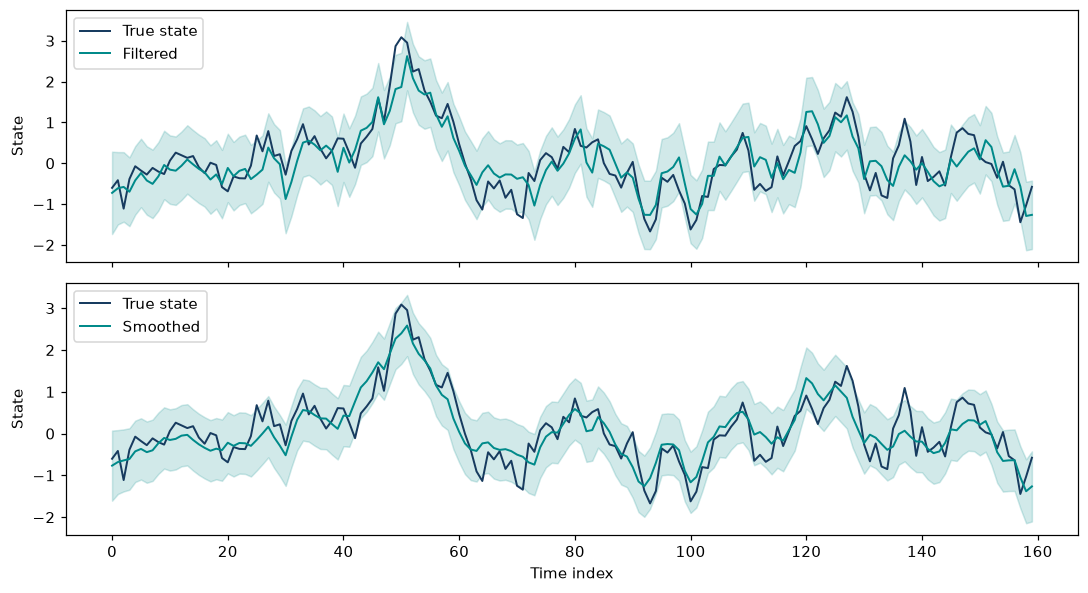

In [2]:
filtered = kalman_filter(data.y, p)
smoothed = rts_smoother(filtered, p)
fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
for ax, result, name in [(axes[0], filtered, "Filtered"), (axes[1], smoothed, "Smoothed")]:
    lower, upper = result.interval()
    ax.fill_between(np.arange(len(data.x)), lower, upper, color="#008a8a", alpha=0.18)
    ax.plot(data.x, color="#173b5f", label="True state", lw=1.3)
    ax.plot(result.mean, color="#008a8a", label=name, lw=1.3)
    ax.legend(loc="upper left")
    ax.set_ylabel("State")
axes[1].set_xlabel("Time index")
fig.tight_layout()
plt.show()
print("Filter MSE:", np.mean((filtered.mean-data.x)**2))
print("Smoother MSE:", np.mean((smoothed.mean-data.x)**2))


## An independent analytic likelihood check
The stationary observation covariance gives a direct multivariate Gaussian likelihood. It is computationally more expensive but provides an independent validation of the sequential recursion.

In [3]:
dense = multivariate_normal.logpdf(data.y, cov=observation_covariance(len(data.y), p))
print("Innovation log likelihood:", filtered.loglikelihood)
print("Dense Gaussian log likelihood:", dense)
print("Absolute difference:", abs(dense-filtered.loglikelihood))
assert np.isclose(dense, filtered.loglikelihood, rtol=1e-11)


Innovation log likelihood: -212.614750744545
Dense Gaussian log likelihood: -212.61475074454503
Absolute difference: 2.842170943040401e-14


## Parameter estimation and its uncertainty
The observation-only MLE fixes alpha and estimates persistence and both variances. These parameter intervals are different from the conditional state bands above. A full-series fit is retrospective and must not be mistaken for real-time parameter learning.

In [4]:
fit = fit_mle(data.y)
print("Estimated parameters:", fit.parameters)
print("Converged:", fit.success, "At boundary:", fit.at_boundary, "Intervals available:", fit.ci_valid)
print(pd.DataFrame({"parameter":["phi","q","r"],
                    "truth":[p.phi,p.q,p.r],
                    "estimate":[fit.parameters.phi,fit.parameters.q,fit.parameters.r],
                    "lower":fit.lower,"upper":fit.upper}).to_string(index=False))


Estimated parameters: Parameters(phi=0.8208842555274025, q=0.27108333801946366, r=0.41436171105473135, alpha=1.0)
Converged: True At boundary: False Intervals available: True
parameter  truth  estimate    lower    upper
      phi   0.85  0.820884 0.562703 0.933155
        q   0.16  0.271083 0.100509 0.731139
        r   0.49  0.414362 0.234246 0.732972


## The scale-equivalence ridge
If loading and latent scale are both free, replacing x by c*x, alpha by alpha/c, and q by c²*q leaves the observation distribution unchanged. State RMSE is meaningless unless estimates and truth use the same units.

In [5]:
ridge_rows=[]
for scale in [0.25, 0.5, 1.0, 2.0, 4.0]:
    changed = rescale_latent(p, scale)
    result = kalman_filter(data.y, changed)
    ridge_rows.append({"scale":scale,"alpha":changed.alpha,"q":changed.q,
                       "loglik_difference":result.loglikelihood-filtered.loglikelihood,
                       "wrong_unit_RMSE":np.sqrt(np.mean((result.mean-data.x)**2)),
                       "correct_unit_RMSE":np.sqrt(np.mean((result.mean/scale-data.x)**2))})
print(pd.DataFrame(ridge_rows).to_string(index=False))


 scale  alpha    q  loglik_difference  wrong_unit_RMSE  correct_unit_RMSE
  0.25   4.00 0.01                0.0         0.699895           0.429041
  0.50   2.00 0.04                0.0         0.573264           0.429041
  1.00   1.00 0.16                0.0         0.429041           0.429041
  2.00   0.50 0.64                0.0         0.778796           0.429041
  4.00   0.25 2.56                0.0         2.073077           0.429041


## Particle filters approximate the Gaussian benchmark
Bootstrap particles propose from the transition. The conditional optimal proposal also uses the current observation. The appropriate numerical error is the discrepancy from the exact conditional mean under the same parameters—not a claim that particles beat the exact solution.

In [6]:
rows=[]
for count in [64,256,2048]:
    for j,proposal in enumerate(["bootstrap","optimal"]):
        result = particle_filter(data.y,p,count,np.random.default_rng(2000+count+j),proposal=proposal)
        rows.append({"proposal":proposal,"particles":count,
                     "MSE_to_exact_mean":np.mean((result.mean-filtered.mean)**2),
                     "mean_ESS_fraction":np.mean(result.ess)/count,
                     "loglik_error":result.loglikelihood-filtered.loglikelihood})
print(pd.DataFrame(rows).to_string(index=False))
print("Single-run comparisons can fluctuate. The saved convergence study averages independent runs.")


 proposal  particles  MSE_to_exact_mean  mean_ESS_fraction  loglik_error
bootstrap         64           0.006874           0.612074     -1.063120
  optimal         64           0.004411           0.685905     -1.896965
bootstrap        256           0.002144           0.600047     -1.522856
  optimal        256           0.001310           0.689821      0.801882
bootstrap       2048           0.000270           0.598921     -0.319091
  optimal       2048           0.000183           0.685819      0.310730
Single-run comparisons can fluctuate. The saved convergence study averages independent runs.


## Inspect the actual 1,000-trial study
Every trial is retained. Monte Carlo uncertainty uses independent trial-level outcomes; time points in a series are not treated as independent replications. Plug-in state intervals omit parameter-estimation uncertainty, which can affect coverage.

In [7]:
results = root / "results" / "full"
states = pd.read_csv(results / "state_trials.csv")
assert states.trial.nunique() == 1000
print("Independent core trials:", states.trial.nunique())
summary = states.groupby("method")[["mse","coverage","interval_width"]].mean()
print(summary.to_string())
print("\nPaired MSE differences:")
print(pd.read_csv(results / "paired_risk_differences.csv").to_string(index=False))


Independent core trials: 1000
                           mse  coverage  interval_width
method                                                  
KF_full_sample_MLE    0.194291  0.928106        1.619260
KF_known              0.183930  0.950638        1.680184
KF_oracle_parameters  0.181591  0.950000        1.664823
PF_bootstrap_known    0.185294  0.944244        1.665909
PF_optimal_known      0.185100  0.944075        1.671994
RTS_full_sample_MLE   0.154215  0.923831        1.427908
RTS_known             0.140795  0.949825        1.469770

Paired MSE differences:
                                           comparison    n      mean     mcse     lower     upper
                    KF_full_sample_MLE minus KF_known 1000  0.010361 0.000988  0.008421  0.012300
                  KF_oracle_parameters minus KF_known 1000 -0.002339 0.000142 -0.002617 -0.002061
                    PF_bootstrap_known minus KF_known 1000  0.001364 0.000111  0.001146  0.001581
                      PF_optimal_known m

## Chronological parameter fitting
The valid holdout fit only sees the training prefix. The deliberately labeled full-sample comparator uses the future and is included to make look-ahead visible.

In [8]:
holdout = pd.read_csv(results / "holdout_trials.csv")
print(holdout.groupby("method")[["mse","coverage","mean_negative_log_predictive_density"]].mean().to_string())


                                mse  coverage  mean_negative_log_predictive_density
method                                                                             
full_sample_MLE_lookahead  0.184029  0.946250                              1.292775
known                      0.181084  0.951813                              1.297893
train_only_MLE             0.191424  0.936937                              1.303720


## A genuinely non-Gaussian extension
For stochastic volatility, observations have conditional variance exp(h). A numerical grid is the reference and the particle filter approximates it. The log-squared-observation Kalman approximation in the complete report is useful but is no longer an exact filter.

Particle MSE to grid conditional mean: 0.00019892581245201842
Maximum grid boundary mass: 4.0124235761678075e-25


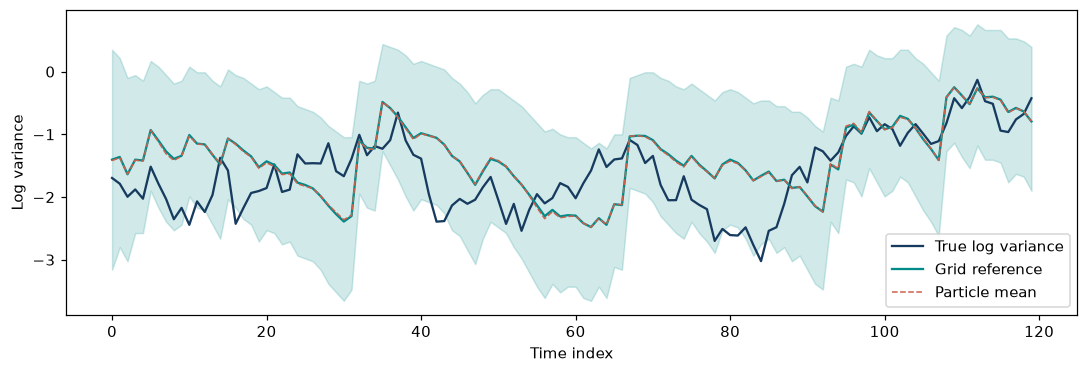

In [9]:
from latent_state_lab.stochastic_volatility import SVParameters, simulate_sv, grid_filter, sv_particle_filter
svp=SVParameters()
h,y=simulate_sv(120,svp,np.random.default_rng(303))
grid=grid_filter(y,svp)
pf=sv_particle_filter(y,svp,2048,np.random.default_rng(404))
fig,ax=plt.subplots(figsize=(10,3.5))
ax.fill_between(np.arange(len(h)),grid.lower,grid.upper,color="#008a8a",alpha=0.18)
ax.plot(h,color="#173b5f",label="True log variance")
ax.plot(grid.mean,color="#008a8a",label="Grid reference")
ax.plot(pf.mean,color="#cb604b",ls="--",label="Particle mean",lw=1)
ax.set(xlabel="Time index",ylabel="Log variance")
ax.legend()
fig.tight_layout()
plt.show()
print("Particle MSE to grid conditional mean:",np.mean((pf.mean-grid.mean)**2))
print("Maximum grid boundary mass:",grid.boundary_mass)


## Further research

- Study profile-likelihood parameter intervals near weak identification.
- Calibrate state intervals that include parameter-estimation uncertainty.
- Estimate contamination parameters instead of supplying their truth.
- Extend to multivariate factor states with a meaningful real-data forecasting question.

Read `docs/METHODS.md` for derivations and `results/full/REPORT.md` for the complete predeclared experiment, failures, uncertainty estimates, and limitations.